# 04 - Baseline models

Three simple models that every later model has to beat:

1. **Dummy** - always predicts the median training price.
2. **Median price per m²** - the median price per m² of the district and property type, times the area.
3. **Ridge regression** - a linear model on one-hot encoded features.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             r2_score, root_mean_squared_error)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

NUMERIC = ["area", "floor_count", "frontage_width", "house_depth", "road_width",
           "bedroom_count", "bathroom_count"]
CATEGORICAL = ["property_type_name", "province_name", "district_name", "ward_name",
               "street_name", "project_name", "house_direction", "balcony_direction"]
FEATURES = NUMERIC + CATEGORICAL

## Data

`trainval` (train + validation) is used to fit and tune, `test` is only used for the final score.

In [2]:
df = pd.read_parquet("../data/processed/model_input.parquet", columns=FEATURES + ["price", "split"])

train = df[df["split"] == "train"]
val = df[df["split"] == "val"]
test = df[df["split"] == "test"]

df["split"].value_counts()

split
train    1677900
test      359551
val       359550
Name: count, dtype: int64

## Metrics

All metrics are computed on the real price (VND), not on the log price. MAE and RMSE are shown in billion VND.

In [3]:
def evaluate(y_true, y_pred):
    return {
        "MAE (bn VND)": mean_absolute_error(y_true, y_pred) / 1e9,
        "RMSE (bn VND)": root_mean_squared_error(y_true, y_pred) / 1e9,
        "R2": r2_score(y_true, y_pred),
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred),
    }


results = {}

## 1. Dummy regressor

In [4]:
dummy = DummyRegressor(strategy="median").fit(train[FEATURES], train["price"])

results["Dummy (median)"] = evaluate(test["price"], dummy.predict(test[FEATURES]))
results["Dummy (median)"]

{'MAE (bn VND)': 11.699590658011127,
 'RMSE (bn VND)': 36.650460990671995,
 'R2': -0.05904202853171436,
 'MAPE (%)': 98.29297622710406}

## 2. Median price per m²

For each (district, property type) group we take the median price per m² in the training set.
A group that does not appear in the training set uses the overall median.

In [5]:
GROUP = ["district_name", "property_type_name"]

price_per_m2 = train["price"] / train["area"]
group_median = train.assign(ppm=price_per_m2).groupby(GROUP)["ppm"].median()

test_ppm = test.join(group_median, on=GROUP)["ppm"].fillna(price_per_m2.median())

results["Median price per m2"] = evaluate(test["price"], test_ppm * test["area"])
results["Median price per m2"]

{'MAE (bn VND)': 7.225137423923218,
 'RMSE (bn VND)': 42.901353192680034,
 'R2': -0.4510964988001511,
 'MAPE (%)': 47.351379505611}

## 3. Ridge regression

Preprocessing is done with a scikit-learn pipeline, so it is always fitted on training rows only:

- numeric: `log1p` -> fill missing values with the median (plus a "was missing" flag) -> standardize,
- categorical: one-hot encoding; levels seen fewer than 50 times are grouped together.

`alpha` is chosen with `GridSearchCV`. `PredefinedSplit` makes it use our time-based validation set instead of random folds.
The best model is then refitted on train + validation.

In [6]:
numeric = make_pipeline(
    FunctionTransformer(np.log1p),
    SimpleImputer(strategy="median", add_indicator=True),
    StandardScaler(),
)
categorical = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)

models, val_mae = {}, {}
for alpha in [1, 10, 100]:
    model = Pipeline([
        ("preprocess", ColumnTransformer([("num", numeric, NUMERIC), ("cat", categorical, CATEGORICAL)])),
        ("model", Ridge(alpha=alpha)),
    ])
    model.fit(train[FEATURES], np.log1p(train["price"]))
    val_pred = np.expm1(model.predict(val[FEATURES]))
    models[alpha] = model
    val_mae[alpha] = mean_absolute_error(val["price"], val_pred) / 1e9

best_alpha = min(val_mae, key=val_mae.get)
print("Validation MAE (bn VND):", val_mae)
print("Best alpha:", best_alpha)

Validation MAE (bn VND): {1: 5.2149001179098065, 10: 5.230331061060758, 100: 5.369164521806635}
Best alpha: 1


In [7]:
trainval = pd.concat([train, val])

final_ridge = Pipeline([
    ("preprocess", ColumnTransformer([("num", numeric, NUMERIC), ("cat", categorical, CATEGORICAL)])),
    ("model", Ridge(alpha=best_alpha)),
])
final_ridge.fit(trainval[FEATURES], np.log1p(trainval["price"]))

ridge_pred = np.expm1(final_ridge.predict(test[FEATURES]))

results["Ridge"] = evaluate(test["price"], ridge_pred)
results["Ridge"]

{'MAE (bn VND)': 5.72987176369095,
 'RMSE (bn VND)': 23.865272609536078,
 'R2': 0.5509578468272371,
 'MAPE (%)': 31.968147365813742}

## Results

In [8]:
table = pd.DataFrame(results).T

os.makedirs("../reports/metrics", exist_ok=True)
table.to_csv("../reports/metrics/04_baselines.csv")

table.style.format("{:,.3f}")

,MAE (bn VND),RMSE (bn VND),R2,MAPE (%)
Dummy (median),11.700,36.650,-0.059,98.293
Median price per m2,7.225,42.901,-0.451,47.351
Ridge,5.730,23.865,0.551,31.968


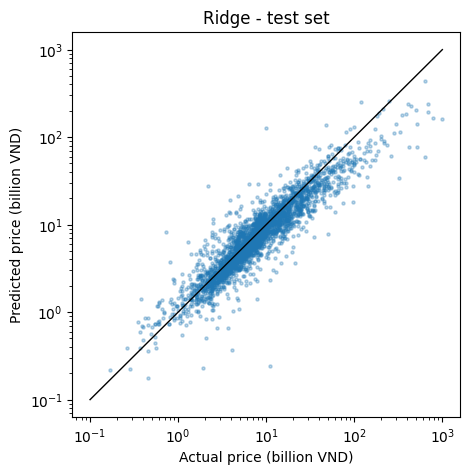

In [9]:
sample = test.assign(pred=ridge_pred).sample(min(3000, len(test)), random_state=42)

plt.figure(figsize=(5, 5))
plt.scatter(sample["price"] / 1e9, sample["pred"] / 1e9, s=5, alpha=0.3)
plt.plot([0.1, 1000], [0.1, 1000], color="black", linewidth=1)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Actual price (billion VND)")
plt.ylabel("Predicted price (billion VND)")
plt.title("Ridge - test set")
plt.show()